# 9. Link Prediction

Lassen sich künftige Begegnungen aus der Netzwerkstruktur vorhersagen? Wir wiederholen das
Experiment von [Liben-Nowell und Kleinberg](https://www.cs.cornell.edu/home/kleinber/link-pred.pdf),
wie es im Skript (Kapitel 12) beschrieben ist: Aus dem Netz eines Trainingszeitraums sagen wir
neue Kanten voraus und prüfen sie an einem späteren Testzeitraum.

- **Training:** Veranstaltungstage 2016 bis 2019. **Test:** 2021 bis 2025. Das Jahr 2020 lassen wir
  weg, da wegen der Pandemie kaum Wettkämpfe stattfanden (Abschnitt 9.4).
- **Kern:** Athleten mit mindestens drei Veranstaltungstagen in beiden Zeiträumen.
- **Verfahren:** vier Netzwerkverfahren (Common Neighbours, Adamic-Adar, Preferential Attachment,
  Soundarajan-Hopcroft) im Vergleich mit drei einfachen Faustregeln aus den Attributen (gleiche
  Nation, ähnlicher Jahrgang, beides kombiniert).

Die Netzwerkverfahren stammen aus NetworkX, die übrigen Hilfsfunktionen liegen in
`link_prediction_utils.py`.

In [1]:
import gc

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter
import networkx as nx
import numpy as np
import pandas as pd

from paths import GRAPHEN, ERGEBNISSE, REPORT_GRAPHICS
from link_prediction_utils import (
    temporal_split, core_nodes, project_events, candidate_pairs,
    network_scores, attribute_scores, evaluate_scores, tie_sensitivity, rank_candidates,
)

EVENTS_PATH = GRAPHEN / 'athlete_events.parquet'
ATTRIBUTES_PATH = ERGEBNISSE / 'assortativitaet/athlete_attributes.parquet'
RESULT_DIR = ERGEBNISSE / 'link_prediction'
REPORT_DIR = REPORT_GRAPHICS
RESULT_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)
SEED = 42
TIE_SEEDS = tuple(range(42, 52))
MIN_EVENTS = 3
METHODS = ['common_neighbours', 'adamic_adar', 'preferential_attachment',
           'soundarajan_hopcroft', 'same_nation', 'birth_year', 'nation_birth_year']
LABELS = ['Common Neighbours', 'Adamic-Adar', 'Preferential Attachment',
          'Soundarajan-Hopcroft', 'Gleiche Nation', 'Ähnlicher Jahrgang', 'Nation + Jahrgang']
SHORT_LABELS = ['Common\nNeighbours', 'Adamic-\nAdar', 'Preferential\nAttachment',
                'Soundarajan-\nHopcroft', 'Gleiche\nNation', 'Ähnlicher\nJahrgang', 'Nation +\nJahrgang']
COLOR, ORANGE, MUTED = '#367da2', '#eb6834', '#a3a29d'
REPORT_RC = {'font.size': 8, 'axes.titlesize': 9, 'axes.labelsize': 8,
             'xtick.labelsize': 7, 'ytick.labelsize': 7, 'pdf.fonttype': 42}
plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e5e4e0', 'grid.linewidth': 0.8,
    'axes.axisbelow': True, 'axes.edgecolor': '#52514e',
    'axes.labelcolor': '#52514e', 'xtick.color': '#52514e', 'ytick.color': '#52514e',
})

## 9.1 Daten aufteilen

Grundlage ist die Zuordnung Athlet zu Veranstaltungstag aus `02_modellierung.ipynb`. Als Attribute
verwenden wir nur Profilnation und Jahrgang aus `07_assortativitaet.ipynb`. Die Profilnation
entspricht dem Stand 2025 und kann sich seit 2016 geändert haben.

In [2]:
raw_events = pd.read_parquet(EVENTS_PATH)
train, test, split_audit = temporal_split(raw_events)
attributes = pd.read_parquet(ATTRIBUTES_PATH, columns=['nation', 'birth_year'])
core = core_nodes(train, test, min_events=MIN_EVENTS)
training_core = core_nodes(train, min_events=MIN_EVENTS)
train_counts = train.groupby('athlete_node')['event_id'].nunique()
test_counts = test.groupby('athlete_node')['event_id'].nunique()
period_summary = pd.DataFrame([
    {'period': name, 'athletes': frame['athlete_node'].nunique(),
     'event_days': frame['event_id'].nunique(), 'participations': len(frame),
     'first_date': str(frame['best_date'].min().date()),
     'last_date': str(frame['best_date'].max().date())}
    for name, frame in [('training_2016_2019', train), ('test_2021_2025', test)]
])
display(period_summary)
display(pd.Series(split_audit, name='Datenprüfung'))
display(attributes.loc[core].isna().sum().rename('Fehlende Werte im Hauptkern'))
print(f'Kern beider Zeiträume: {len(core):,}; nur Training: {len(training_core):,}')

,period,athletes,event_days,participations,first_date,last_date
0,training_2016_2019,7024,14748,56703,2016-01-03,2019-12-30
1,test_2021_2025,6062,14662,67601,2021-01-04,2025-04-08


input_rows            238942
excluded_2020_rows      5749
train_rows             56703
test_rows              67601
train_athletes          7024
test_athletes           6062
train_event_days       14748
test_event_days        14662
Name: Datenprüfung, dtype: int64

nation        0
birth_year    0
Name: Fehlende Werte im Hauptkern, dtype: int64

Kern beider Zeiträume: 3,017; nur Training: 5,594


## 9.2 Trainings- und Testnetz

Training und Test werden getrennt projiziert. Anders als im Arbeitsnetz reicht hier ein
gemeinsamer Tag für eine Kante, sonst würden Paare, die sich im Training schon begegnet sind,
als neue Kandidaten gelten. Für Soundarajan-Hopcroft bestimmen wir Communities mit Louvain auf dem
Trainingsnetz (T1, T2, …). Sie sind unabhängig von den Generationen C1 bis C4.

Kandidaten sind alle Paare von Kernathleten, die im Training nicht verbunden sind. Ein Kandidat
gilt als neue Kante, wenn die beiden im Test mindestens einen gemeinsamen Tag haben.

In [3]:
train_nodes, train_weights = project_events(train)
train_index = pd.Index(train_nodes)
A = train_weights.copy()
A.data[:] = 1
test_nodes, test_weights = project_events(test)
test_index = pd.Index(test_nodes)
G_train = nx.from_scipy_sparse_array(A)
partition = sorted(nx.community.louvain_communities(
    G_train, weight=None, resolution=1, seed=SEED), key=lambda group: (-len(group), min(group)))
communities = np.empty(len(train_nodes), dtype=np.int32)
for c, members in enumerate(partition):
    communities[list(members)] = c
modularity = nx.community.modularity(G_train, partition, weight=None)
nx.set_node_attributes(G_train, dict(enumerate(communities.tolist())), 'community')
print(f'Training: {len(train_nodes):,} Athleten, {A.nnz // 2:,} Kanten, '
      f'{len(partition)} Communities, Q = {modularity:.4f}')
print(f'Test: {len(test_nodes):,} Athleten, {test_weights.nnz // 2:,} Kanten')

def candidate_test_weights(population, pairs):
    """Gemeinsame Testtage der Kandidatenpaare (0, wenn ein Athlet im Test fehlt)."""
    positions = test_index.get_indexer(population)
    left, right = positions[pairs[0]], positions[pairs[1]]
    known = (left >= 0) & (right >= 0)
    weights = np.zeros(len(left), dtype=np.int32)
    weights[known] = np.asarray(test_weights[left[known], right[known]]).ravel()
    return weights

core_indices = train_index.get_indexer(core)
pairs = candidate_pairs(A, core_indices)
observed_test_weights = candidate_test_weights(core, pairs)
labels = observed_test_weights >= 1
repeat_labels = observed_test_weights >= 2
main_train_edges = A[core_indices][:, core_indices].nnz // 2
display(pd.Series({'Kernathleten': len(core), 'Kanten zwischen Kernathleten (Training)': main_train_edges,
                   'Kandidatenpaare': len(labels), 'Neue Kanten im Test': int(labels.sum()),
                   'davon mit mindestens zwei Testtagen': int(repeat_labels.sum())},
                  name='Anzahl').to_frame())
print(f'Zufallspräzision Hauptanalyse: {labels.mean():.6%}; wiederholt: {repeat_labels.mean():.6%}')

Training: 7,024 Athleten, 260,719 Kanten, 224 Communities, Q = 0.5357
Test: 6,062 Athleten, 387,049 Kanten


,Anzahl
Kernathleten,3017
Kanten zwischen Kernathleten (Training),50792
Kandidatenpaare,4498844
Neue Kanten im Test,121753
davon mit mindestens zwei Testtagen,32636


Zufallspräzision Hauptanalyse: 2.706317%; wiederholt: 0.725431%


## 9.3 Scores

Jedes Verfahren gibt jedem Kandidatenpaar einen Score, höhere Scores gelten als wahrscheinlichere
neue Kanten. Die Netzwerkverfahren berechnen wir mit den NetworkX-Funktionen auf dem ganzen
Trainingsnetz.

| Verfahren | Score |
| --- | --- |
| Common Neighbours | Anzahl gemeinsamer Nachbarn |
| Adamic-Adar | Gemeinsame Nachbarn, gewichtet mit $1/\ln(\text{Degree})$: seltene Nachbarn zählen mehr |
| Preferential Attachment | Produkt der beiden Degrees |
| Soundarajan-Hopcroft | Gemeinsame Nachbarn, doppelt gezählt, wenn alle drei Athleten in derselben Trainingscommunity sind |
| Gleiche Nation | 1 bei gleicher Profilnation, sonst 0 |
| Ähnlicher Jahrgang | Negative Jahrgangsdifferenz |
| Nation + Jahrgang | Zuerst gleiche Nation, danach kleinere Jahrgangsdifferenz |

In [4]:
scores = network_scores(G_train, core_indices[pairs[0]], core_indices[pairs[1]])
scores.update(attribute_scores(attributes.loc[core], pairs))
display(pd.DataFrame({name: {'minimum': float(s.min()), 'maximum': float(s.max()),
                           'zero_share': float(np.mean(s == 0))} for name, s in scores.items()}).T)

,minimum,maximum,zero_share
common_neighbours,0.0,258.000000,0.783145
adamic_adar,0.0,44.525325,0.783145
preferential_attachment,0.0,302451.000000,0.018687
soundarajan_hopcroft,0.0,463.000000,0.783145
same_nation,0.0,1.000000,0.987555
birth_year,-39.0,-0.000000,0.075717
nation_birth_year,-39.0,41.000000,0.074878


## 9.4 Evaluation

$K$ ist die Zahl der tatsächlich neuen Kanten im Test. Jedes Verfahren wählt seine $K$ besten
Paare, die Precision@K ist der Anteil davon, der tatsächlich neu verbunden ist. Der Faktor
vergleicht mit einer zufälligen Auswahl, deren Trefferquote $K$ / Anzahl Kandidaten beträgt.
$K$ ist erst im Nachhinein bekannt, bei einer echten Vorhersage müsste man es schätzen.

Viele Paare haben denselben Score, etwa keine gemeinsamen Nachbarn. Solche Gleichstände lösen wir
zufällig auf und wiederholen das mit zehn Seeds, um zu sehen, wie stark das Ergebnis davon abhängt.

In [5]:
main_results = evaluate_scores(scores, labels, seed=SEED).assign(scenario='main')
repeat_results = evaluate_scores(scores, repeat_labels, seed=SEED).assign(scenario='repeated_test')
ties = pd.concat([
    tie_sensitivity(scores, labels, seeds=TIE_SEEDS).assign(scenario='main'),
    tie_sensitivity(scores, repeat_labels, seeds=TIE_SEEDS).assign(scenario='repeated_test'),
], ignore_index=True)
display(main_results[['method', 'k', 'true_positives', 'precision_at_k', 'random_precision', 'lift']])
tie_summary = ties.groupby(['scenario', 'method'], sort=False).agg(
    precision_min=('precision_at_k', 'min'), precision_max=('precision_at_k', 'max'),
    lift_min=('lift', 'min'), lift_max=('lift', 'max'))
display(tie_summary.loc['main'])


,method,k,true_positives,precision_at_k,random_precision,lift
0,common_neighbours,121753,17967,0.147569,0.027063,5.452770
1,adamic_adar,121753,19334,0.158797,0.027063,5.867638
2,preferential_attachment,121753,5792,0.047572,0.027063,1.757803
3,soundarajan_hopcroft,121753,20388,0.167454,0.027063,6.187514
4,same_nation,121753,30612,0.251427,0.027063,9.290376
5,birth_year,121753,4575,0.037576,0.027063,1.388458
6,nation_birth_year,121753,31217,0.256396,0.027063,9.473986


,precision_min,precision_max,lift_min,lift_max
method,,,,
common_neighbours,0.147512,0.147709,5.450645,5.457929
adamic_adar,0.158797,0.158797,5.867638,5.867638
preferential_attachment,0.047572,0.047580,1.757803,1.758106
soundarajan_hopcroft,0.167199,0.167610,6.178106,6.193281
same_nation,0.250614,0.251673,9.260331,9.299481
birth_year,0.037420,0.038866,1.382692,1.436105
nation_birth_year,0.256183,0.257250,9.466096,9.505549


### Warum die Nation so gut vorhersagt

Drei Auswertungen helfen beim Einordnen: die Teilnahmen pro Jahr (Ausschluss von 2020), der
Anteil der grössten Nation in den Trainingscommunities und der Anteil von Landsleuten unter den
besten Paaren jedes Netzwerkverfahrens.

In [6]:
year_counts = pd.to_datetime(raw_events['best_date']).dt.year.value_counts().sort_index().loc[2016:2021]
display(year_counts.rename('Teilnahmen').to_frame())

train_nations = pd.Series(attributes['nation'].reindex(train_nodes).to_numpy())
community_purity = train_nations.groupby(communities).agg(lambda s: s.value_counts(normalize=True).iloc[0])
community_sizes = pd.Series(communities).value_counts()
weighted_purity = (community_purity * community_sizes.reindex(community_purity.index)).sum() / community_sizes.sum()
print(f'Trainingscommunities: Anteil der grössten Nation im Mittel (gewichtet) {weighted_purity:.1%}')

k = int(labels.sum())
same_nation = scores['same_nation'].astype(bool)
nation_share = pd.Series({
    **{LABELS[METHODS.index(m)]: same_nation[rank_candidates(scores[m], seed=SEED)[:k]].mean()
       for m in METHODS[:4]},
    'Alle Kandidaten': same_nation.mean(),
    'Neue Testkanten': same_nation[labels].mean(),
}, name='Anteil gleiche Nation')
display(nation_share.map('{:.1%}'.format).to_frame())

same_year = scores['birth_year'] == 0
display(pd.Series({
    'Landsleute unter den Kandidaten': int(same_nation.sum()),
    'davon im Test neu verbunden': f'{labels[same_nation].mean():.1%}',
    'Gleichaltrige unter den Kandidaten': int(same_year.sum()),
    'davon im Test neu verbunden ': f'{labels[same_year].mean():.1%}',
}, name='Neue Kanten je Gruppe').to_frame())

,Teilnahmen
best_date,
2016,13276
2017,13263
2018,13937
2019,16227
2020,5749
2021,13084


Trainingscommunities: Anteil der grössten Nation im Mittel (gewichtet) 33.7%


,Anteil gleiche Nation
Common Neighbours,16.6%
Adamic-Adar,18.8%
Preferential Attachment,0.7%
Soundarajan-Hopcroft,19.9%
Alle Kandidaten,1.2%
Neue Testkanten,24.0%


,Neue Kanten je Gruppe
Landsleute unter den Kandidaten,55986
davon im Test neu verbunden,52.2%
Gleichaltrige unter den Kandidaten,340638
davon im Test neu verbunden,3.8%


Das Jahr 2020 fällt mit nur 5'749 Teilnahmen aus der Reihe, in den Jahren davor und danach sind es jeweils über 13'000. Wegen der Corona-Pandemie fanden kaum Wettkämpfe statt. Deshalb bleibt 2020 ausgeschlossen und trennt zugleich Training und Test.

Fast ein Viertel der neuen Kanten (24.0 %) verbindet Landsleute, obwohl sie nur 1.2 % der Kandidaten ausmachen. Von den 55'986 Kandidatenpaaren aus Landsleuten begegnet sich mehr als die Hälfte (52.2 %) im Testzeitraum, über alle Kandidaten sind es 2.7 %. Nationale Meisterschaften wiederholen sich jedes Jahr und bringen Landsleute zusammen, deshalb ist die Faustregel gleiche Nation so stark. Die Netzwerkverfahren erfassen dieses Muster nur teilweise. Unter den besten Paaren von Common Neighbours, Adamic-Adar und Soundarajan-Hopcroft sind 17 bis 20 % Landsleute. Die Trainingscommunities sind gemischt (grösste Nation im Mittel 34 %), der Community-Bonus von Soundarajan-Hopcroft verbessert die Vorhersage trotzdem.

Gleichaltrige Paare gibt es viele (340'638), aber nur 3.8 % davon begegnen sich im Test, kaum mehr als über alle Kandidaten. Die hohe Jahrgangsassortativität (r = 0.85, `07_assortativitaet.ipynb`) bedeutet also nicht, dass sich der Jahrgang gut zur Vorhersage eignet.

## 9.5 Robustheit

Zwei Varianten prüfen, ob die Rangfolge der Verfahren stabil bleibt:

- **Wiederholte Begegnungen:** Als neu gilt ein Paar erst mit mindestens zwei gemeinsamen Testtagen.
- **Kern nur aus dem Training:** Athleten mit mindestens drei Trainingstagen, unabhängig davon, ob sie
  im Test noch aktiv sind. Die Auswahl hängt damit nicht mehr vom Testzeitraum ab.

$K$ und Zufallsbasis ändern sich mit jeder Variante. Die Faktoren sind deshalb nur innerhalb einer
Variante vergleichbar.

In [7]:
# Speicher freigeben: Die zweite Variante hat über 15 Millionen Kandidaten.
del scores, pairs, observed_test_weights, labels, repeat_labels
gc.collect()
training_indices = train_index.get_indexer(training_core)
training_pairs = candidate_pairs(A, training_indices)
training_labels = candidate_test_weights(training_core, training_pairs) >= 1
training_scores = network_scores(G_train, training_indices[training_pairs[0]], training_indices[training_pairs[1]])
training_scores.update(attribute_scores(attributes.loc[training_core], training_pairs))
training_results = evaluate_scores(training_scores, training_labels, seed=SEED).assign(scenario='training_only')
results = pd.concat([main_results, repeat_results, training_results], ignore_index=True)
training_core_edges = A[training_indices][:, training_indices].nnz // 2
split_summary = pd.DataFrame([
    {'scenario': name, 'core_athletes': population, 'training_core_edges': edges,
     'candidate_pairs': int(frame['n_candidates'].iloc[0]), 'new_test_edges': int(frame['k'].iloc[0]),
     'random_precision': float(frame['random_precision'].iloc[0])}
    for name, population, edges, frame in [
        ('main', len(core), main_train_edges, main_results),
        ('repeated_test', len(core), main_train_edges, repeat_results),
        ('training_only', len(training_core), training_core_edges, training_results)]
])
display(split_summary)
display(results.pivot(index='method', columns='scenario', values=['precision_at_k', 'lift']).reindex(METHODS))
del training_scores, training_pairs, training_labels
gc.collect()

,scenario,core_athletes,training_core_edges,candidate_pairs,new_test_edges,random_precision
0,main,3017,50792,4498844,121753,0.027063
1,repeated_test,3017,50792,4498844,32636,0.007254
2,training_only,5594,234125,15409496,129358,0.008395


precision_at_k                                  lift  \
scenario                          main repeated_test training_only      main   
method                                                                         
common_neighbours             0.147569      0.074458      0.028495  5.452770   
adamic_adar                   0.158797      0.100564      0.039000  5.867638   
preferential_attachment       0.047572      0.007783      0.009880  1.757803   
soundarajan_hopcroft          0.167454      0.126701      0.050774  6.187514   
same_nation                   0.251427      0.311864      0.202995  9.290376   
birth_year                    0.037576      0.010541      0.014116  1.388458   
nation_birth_year             0.256396      0.386904      0.225684  9.473986   

                                                     
scenario                repeated_test training_only  
method                                               
common_neighbours           10.263922      3.394354  
adamic_adar                 13.862631      4.645827  
preferential_attachment      1.072854      1.176881  
soundarajan_hopcroft        17.465563      6.048323  
same_nation                 42.990207     24.181322  
birth_year                   1.453000      1.681522  
nation_birth_year           53.334382     26.884097

0

## 9.6 Abbildungen

Blau sind die Netzwerkverfahren, Orange die Faustregeln, gestrichelt der Zufall. Die schwarzen
Striche in der ersten Abbildung zeigen die Spannweite über die zehn Seeds.

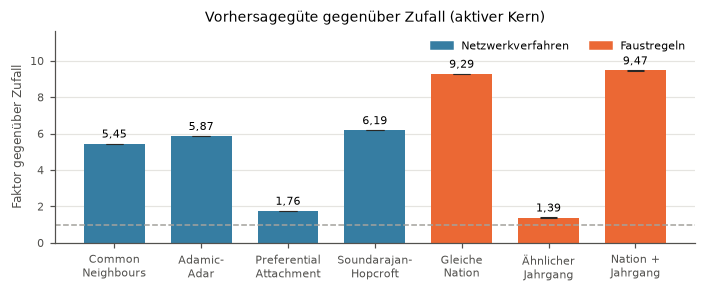

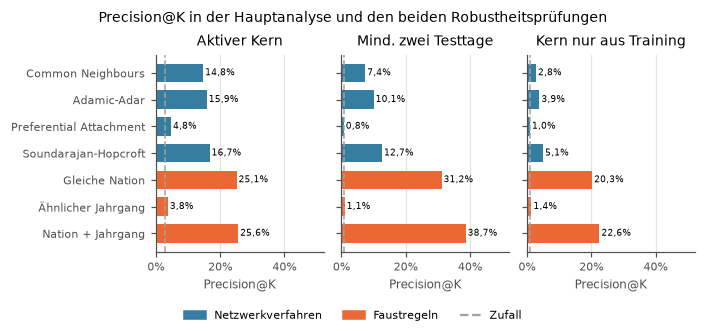

In [8]:
main_ordered = main_results.set_index('method').loc[METHODS]
colors = [COLOR] * 4 + [ORANGE] * 3
x = np.arange(len(METHODS))
with plt.rc_context(REPORT_RC):
    fig, ax = plt.subplots(figsize=(6.3, 2.55), layout='constrained')
    ax.bar(x, main_ordered['lift'], color=colors, width=0.7)
    span = tie_summary.loc['main'].loc[METHODS]
    ax.vlines(x, span['lift_min'], span['lift_max'], color='#292826', linewidth=1.2)
    ax.hlines(span['lift_min'], x - .10, x + .10, color='#292826', linewidth=.7)
    ax.hlines(span['lift_max'], x - .10, x + .10, color='#292826', linewidth=.7)
    for xi, value in zip(x, main_ordered['lift']):
        ax.annotate(f'{value:.2f}'.replace('.', ','), (xi, value), xytext=(0, 4),
                    textcoords='offset points', ha='center', fontsize=7)
    ax.axhline(1, color=MUTED, linestyle='--', linewidth=1)
    ax.set(xticks=x, xticklabels=SHORT_LABELS, ylabel='Faktor gegenüber Zufall',
           ylim=(0, main_ordered['lift'].max() * 1.23),
           title='Vorhersagegüte gegenüber Zufall (aktiver Kern)')
    ax.grid(axis='x', visible=False)
    ax.legend(handles=[Patch(color=COLOR, label='Netzwerkverfahren'),
                       Patch(color=ORANGE, label='Faustregeln')], frameon=False,
              loc='upper right', ncols=2, fontsize=7)
    fig.savefig(REPORT_DIR / '09_link_prediction.pdf', bbox_inches='tight',
                metadata={'CreationDate': None, 'ModDate': None})
    plt.show()

with plt.rc_context(REPORT_RC):
    fig, axes = plt.subplots(1, 3, figsize=(6.3, 2.9), sharey=True, layout='constrained')
    for ax, scenario, title in zip(axes, ['main', 'repeated_test', 'training_only'],
                                    ['Aktiver Kern', 'Mind. zwei Testtage', 'Kern nur aus Training']):
        frame = results[results['scenario'].eq(scenario)].set_index('method').loc[METHODS]
        ax.barh(x, frame['precision_at_k'], color=colors, height=.7)
        ax.axvline(frame['random_precision'].iloc[0], color=MUTED, linestyle='--', linewidth=1)
        for yi, value in zip(x, frame['precision_at_k']):
            ax.text(value + .006, yi, f'{value:.1%}'.replace('.', ','), va='center', fontsize=6)
        ax.set(title=title, xlabel='Precision@K', xlim=(0, results['precision_at_k'].max() * 1.35))
        ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
        ax.grid(axis='y', visible=False)
    axes[0].set_yticks(x, LABELS)
    axes[0].invert_yaxis()
    fig.legend(handles=[Patch(color=COLOR, label='Netzwerkverfahren'),
                        Patch(color=ORANGE, label='Faustregeln'),
                        plt.Line2D([], [], color=MUTED, linestyle='--', label='Zufall')],
               loc='outside lower center', ncols=3, frameon=False, fontsize=7)
    fig.suptitle('Precision@K in der Hauptanalyse und den beiden Robustheitsprüfungen', fontsize=9)
    fig.savefig(REPORT_DIR / '09_precision_robustheit.pdf', bbox_inches='tight',
                metadata={'CreationDate': None, 'ModDate': None})
    plt.show()

## 9.7 Einordnung

Soundarajan-Hopcroft verbessert Common Neighbours um 2.0 Prozentpunkte (16.7 % statt 14.8 %). Die
Trainingscommunities helfen also, obwohl sie national gemischt sind. Preferential Attachment ist
kaum besser als der Zufall, da ein hoher Degree oft durch wenige grosse Veranstaltungen entsteht.
In beiden Robustheitsprüfungen bleiben die Nationsregeln vorne, gefolgt von Soundarajan-Hopcroft.

Grenzen:

- Die Daten enthalten nur Karrierebestzeiten. Eine neue Testkante kann deshalb auch eine frühere,
  nicht mehr erfasste Begegnung sein, etwa vor 2016 oder 2020.
- Der Kern ist anhand beider Zeiträume ausgewählt, und $K$ ist erst im Nachhinein bekannt.
- Die Profilnation entspricht dem Stand 2025, der Testzeitraum endet am 8. April 2025.
- Vorhergesagt werden gemeinsame Bestleistungstage, keine persönlichen Kontakte.

## 9.8 Export

Gespeichert werden die Auswertung aller Verfahren in den drei Varianten und die Ergebnisse über die
zehn Seeds.

In [9]:
results.to_parquet(RESULT_DIR / 'evaluation.parquet', index=False)
ties.to_parquet(RESULT_DIR / 'tie_sensitivity.parquet', index=False)

## Erkenntnisse

- Die Netzwerkverfahren ausser Preferential Attachment treffen fünf- bis sechsmal so oft wie der
  Zufall, am besten Soundarajan-Hopcroft mit einer Precision@K von 16.7 %.
- Die einfache Faustregel gleiche Nation erreicht 25.1 %, kombiniert mit dem Jahrgang 25.6 %. Mehr
  als die Hälfte der Landsleute, die sich im Training nicht begegnet sind, treffen sich im Test,
  vermutlich an jährlich wiederkehrenden nationalen Meisterschaften.
- Die Netzwerkstruktur sagt neue Begegnungen also deutlich besser voraus als der Zufall, aber
  schlechter als die Nation allein. Die Rangfolge bleibt in beiden Robustheitsprüfungen gleich.